In [1]:
import numpy as np
import pandas as pd
import torch
import h5py
import joblib
import os, sys
import subprocess
import matplotlib.pyplot as plt
import math, json

In [2]:
import sys
sys.path.insert(0, "/mnt/efsUCE/umap_pytorch")  #git+https://github.com/ucscBrainExplorer/umap_pytorch.git
import umap_pytorch
print(umap_pytorch.__file__)

/mnt/efsUCE/umap_pytorch/umap_pytorch/__init__.py


In [20]:
results_dir = "/mnt/efsUCE/combined_UCE_5neuro_ucebrain768bican_shuffle/"

embedding_h5_file = "pca_corrected_k3.h5"
embedding_h5_file_key = "pca"
knn_outfile = "knn_30_ivfflat.npz"
k = 10
batch_size= 2048 #1024 #512, #256, #64, # gpu memory related

existing_model_iteration = 1
epochs = 1

# One results_dir can hold several tries (e.g. different batch corrections). run_tag goes into every
# output name: pytorch_k3_e5.pkl, transform_k3_e5.json, umap_k3_e5.npy. "" keeps the old names.
run_tag = "k5"
tag = f"_{run_tag}" if run_tag else ""
# Training on a batch-corrected PCA (e.g. pca_corrected_k3.h5): set its directions file (batch_dirs_k3.npy)
# so the transform config gets "d_hat" and map_newdata.py removes the same directions from new data.
d_hat_file = None
tag

'_k5'

## Load Embedding back into memory

In [4]:
# Load the embedding data
# Open the HDF5 file
with h5py.File(os.path.join(results_dir, embedding_h5_file), "r") as f:
    X_data = f[embedding_h5_file_key][:]

# Convert to PyTorch tensor so to use gpu
data_tensor = torch.from_numpy(X_data)
data_tensor, data_tensor.shape

(tensor([[ 0.1764, -0.0285, -0.0163,  ..., -0.0344,  0.0097, -0.0464],
         [ 0.0031,  0.3957, -0.1234,  ..., -0.0105,  0.0167, -0.0223],
         [-0.2879,  0.0127,  0.0464,  ...,  0.0415, -0.0478, -0.0666],
         ...,
         [ 0.0840, -0.0362,  0.6044,  ..., -0.0737,  0.0406,  0.0252],
         [ 0.4544, -0.3630,  0.0324,  ..., -0.0065,  0.0163,  0.0031],
         [-0.5055, -0.2202, -0.0689,  ...,  0.0111, -0.0613, -0.0168]]),
 torch.Size([7100746, 50]))

## Load Knn Back

In [5]:
# load knn back
data = np.load(os.path.join(results_dir, knn_outfile))
knn_indices = data["indices"]
knn_distances = data["distances"]

In [6]:
knn_distances = np.sqrt(knn_distances)

## PUMAP 
using umap_pytorch https://github.com/ucscBrainExplorer/umap_pytorch.git

## set up training on all cells

In [7]:
knn_indices = knn_indices[:,:k]
knn_dists = knn_distances[:,:k]

### Load model back or start with a new model

In [8]:
if existing_model_iteration > 0:
    from umap_pytorch import load_pumap
    path = os.path.join(results_dir, f'pytorch{tag}_e{existing_model_iteration}.pkl')
    pumap = load_pumap(path)
    pumap.epochs = epochs
    print ("Start with existing model", f'pytorch{tag}_e{existing_model_iteration}.pkl')
else:
    import torch.nn.functional as F
    pumap = umap_pytorch.PUMAP(
        encoder=None,           # nn.Module, None for default
        decoder=None,           # nn.Module, True for default, None for encoder only
        n_neighbors=10,
        min_dist= 0.2, # default 0.1
        metric="euclidean",
        n_components=2,
        beta=1.0,               # How much to weigh reconstruction loss for decoder
        reconstruction_loss=F.binary_cross_entropy_with_logits, # pass in custom reconstruction loss functions
        random_state=None,
        lr=1e-3,
        epochs=epochs, #5,
        batch_size= batch_size,
        num_workers=0, #10,
        num_gpus=1,
        match_nonparametric_umap=False, # Train network to match embeddings from non parametric umap,
    )
    print ("Start with a new model")

Loading PUMAP object from pickled file.
Start with existing model pytorch_k3_e1.pkl


### Train

In [9]:
existing_model_iteration, pumap.epochs

(1, 1)

In [ ]:
np.product = np.prod  # alias to fix compatibility
pumap.fit(data_tensor, knn_indices, knn_dists)

💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
/home/ec2-user/.local/lib/python3.9/site-packages/pytorch_lightning/trainer/connectors/logger_connector/logger_connector.py:76: Starting from v1.9.0, `tensorboardX` has been removed as a dependency of the `pytorch_lightning` package, due to potential conflicts with other packages in the ML ecosystem. For this reason, `logger=True` will use `CSVLogger` as the default logger, unless the `tensorboard` or `tensorboardX` packages are found. Please `pip install lightning[extra]` or one of them to enable TensorBoard support by default


Fitting parametric Umap
There are knn provided by the user
Start fuzzy_simplicial_set ...


### Saving model

In [11]:
existing_model_iteration = existing_model_iteration+ pumap.epochs
existing_model_iteration

1

In [12]:
model_path = os.path.join(results_dir, f'pytorch{tag}_e{existing_model_iteration}.pkl')
pumap.save(model_path)

Pickled PUMAP object at /mnt/efsUCE/combined_UCE_5neuro_ucebrain768bican_shuffle/pytorch_e1.pkl


### Quick viz X_umap_pytorch

In [21]:
# load model
from umap_pytorch import load_pumap
model_path = os.path.join(results_dir, f'pytorch{tag}_e{existing_model_iteration}.pkl')
pumap = load_pumap(model_path)
print("Loaded model", f'pytorch{tag}_e{existing_model_iteration}.pkl')

Loading PUMAP object from pickled file.
Loaded model pytorch_k5_e1.pkl


#### random 500K

In [22]:
view_size = 500_000
if X_data.shape[0] < view_size:
    subset_indices = range (0, X_data.shape[0])
else:
    np.random.seed(42)  # set seed for reproducibility
    subset_indices = np.random.choice(X_data.shape[0], size= view_size, replace=False)

In [23]:
X_umap_pytorch = pumap.transform(data_tensor[subset_indices])

Reducing array of shape torch.Size([500000, 50]) to (500000, 2)


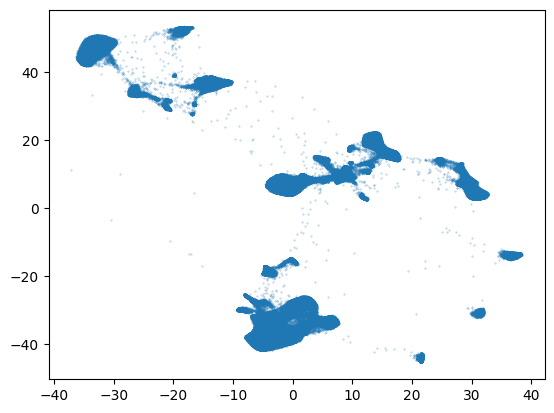

In [24]:
# current
plt.scatter(X_umap_pytorch[:,0], X_umap_pytorch[:,1], alpha =0.5, s=0.1)
plt.show()

## optional quick viz with metadata

In [14]:
metadata_file = "obs.tsv.gz"
usecols = ["cell_type", "collection_doi_label", "dataset_title", "assay"]
metadata = pd.read_csv(os.path.join(results_dir, metadata_file), sep ='\t', usecols = usecols)

In [15]:
metadata.columns

Index(['cell_type', 'collection_doi_label', 'dataset_title'], dtype='object')

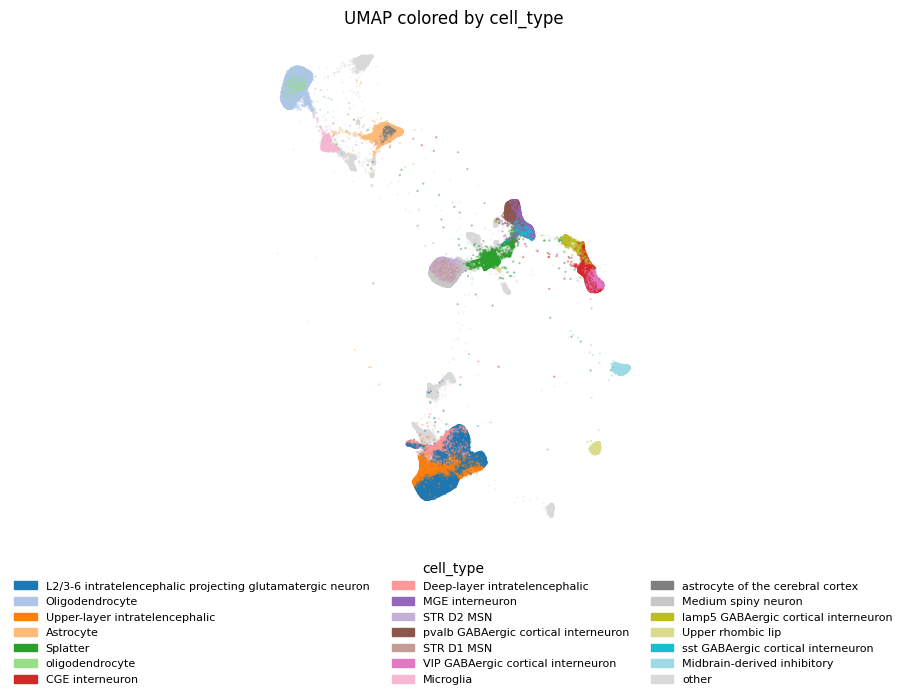

In [25]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

metadata_feature = "cell_type"
top_n = 20

colors = metadata[metadata_feature].iloc[subset_indices].astype(str).to_numpy()
top_cats = list(pd.Series(colors).value_counts().nlargest(top_n).index)
labels = np.where(np.isin(colors, top_cats), colors, "other")

palette = plt.get_cmap("tab20").colors
color_map = {cat: palette[i] for i, cat in enumerate(top_cats)}

is_other = labels == "other"
rng = np.random.default_rng(0)
idx = rng.permutation(np.flatnonzero(~is_other))

fig, ax = plt.subplots(figsize=(7, 7))
# "other" in light grey, underneath
ax.scatter(X_umap_pytorch[is_other, 0], X_umap_pytorch[is_other, 1],
           color=(0.85, 0.85, 0.85), s=0.3, alpha=0.3, rasterized=True)
# top categories in shuffled order on top
ax.scatter(X_umap_pytorch[idx, 0], X_umap_pytorch[idx, 1],
           c=[color_map[l] for l in labels[idx]], s=0.3, alpha=0.5, rasterized=True)
ax.set_aspect("equal", adjustable="datalim")
ax.axis("off")
ax.set_title(f"UMAP colored by {metadata_feature}")

patches = [mpatches.Patch(color=color_map[c], label=c) for c in top_cats]
if is_other.any():
    patches.append(mpatches.Patch(color=(0.85, 0.85, 0.85), label="other"))
fig.legend(handles=patches, title=metadata_feature, loc="lower center",
           bbox_to_anchor=(0.5, 0), ncol=3, frameon=False, fontsize=8)
fig.tight_layout(rect=(0, 0.2, 1, 1))  # room for the legend
plt.show()

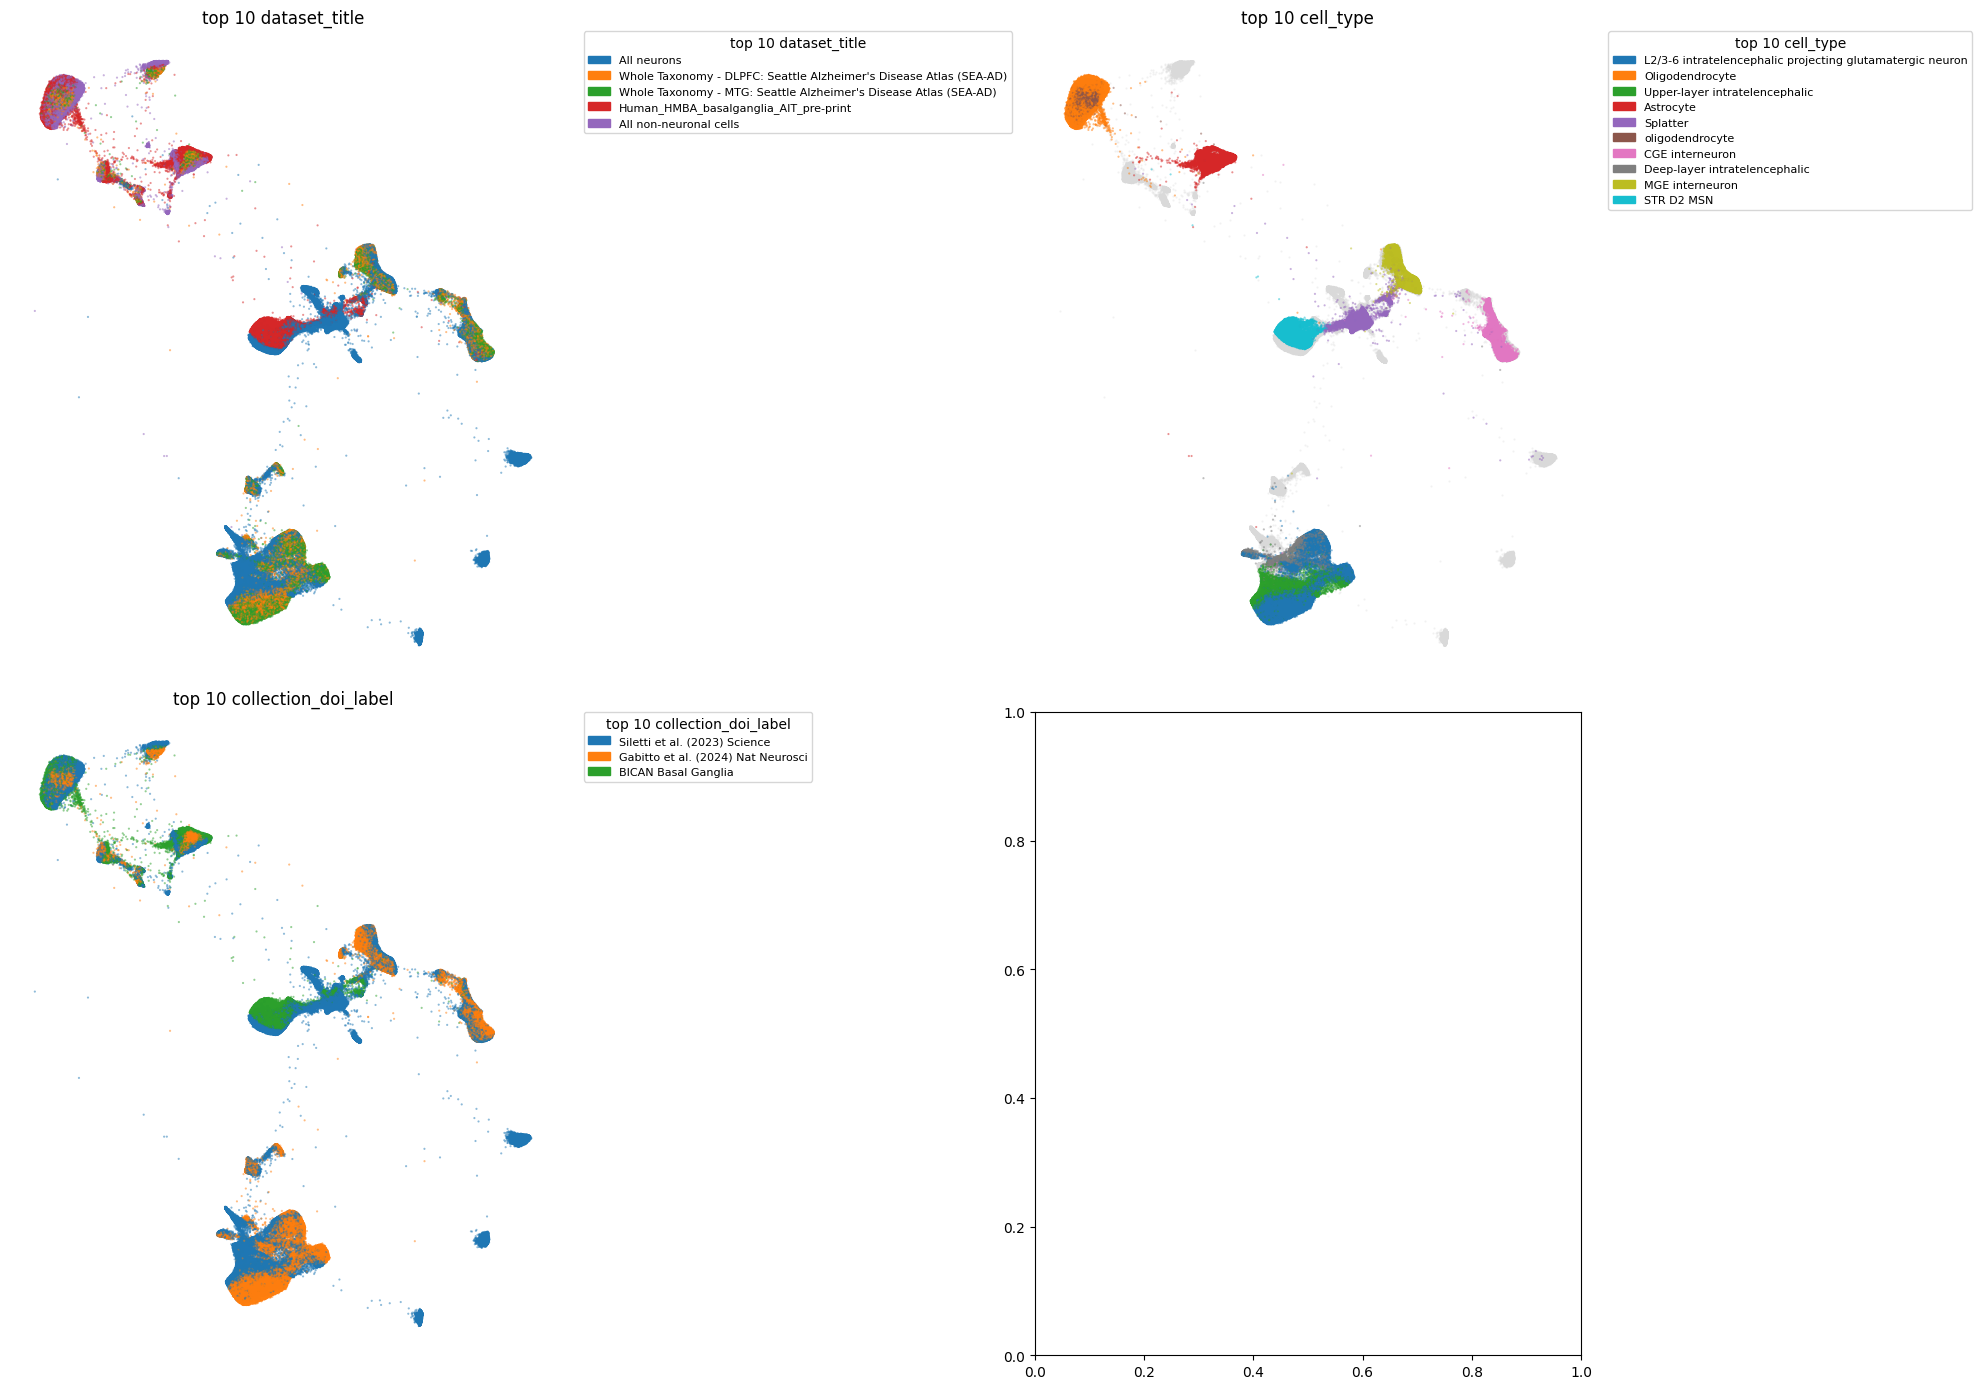

In [26]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

features = ["dataset_title", "cell_type", "collection_doi_label"]
top_n = 10
rng = np.random.default_rng(0)

fig, axes = plt.subplots(2, 2, figsize=(20, 14))
axes = axes.flatten()

for ax, metadata_feature in zip(axes, features):
    colors = metadata[metadata_feature].iloc[subset_indices].astype(str).to_numpy()
    top_cats = pd.Series(colors).value_counts().nlargest(top_n).index
    labels = np.where(np.isin(colors, top_cats), colors, "other")
    unique_cats = list(top_cats)  # frequency order

    cmap = plt.get_cmap("tab10")
    color_map = {cat: cmap(i) for i, cat in enumerate(unique_cats)}

    is_other = labels == "other"

    # 1) "other" in the background
    ax.scatter(X_umap_pytorch[is_other, 0], X_umap_pytorch[is_other, 1],
               color=(0.85, 0.85, 0.85), alpha=0.3, s=0.3, rasterized=True)

    # 2) top categories on top, in random order
    idx = rng.permutation(np.flatnonzero(~is_other))
    ax.scatter(X_umap_pytorch[idx, 0], X_umap_pytorch[idx, 1],
               c=[color_map[l] for l in labels[idx]], alpha=0.5, s=0.3, rasterized=True)

    patches = [mpatches.Patch(color=color_map[cat], label=cat) for cat in unique_cats]
    ax.legend(handles=patches, title=f"top {top_n} {metadata_feature}",
              bbox_to_anchor=(1.05, 1), loc="upper left", borderaxespad=0, fontsize=8)
    ax.axis("off")
    ax.set_title(f"top {top_n} {metadata_feature}")

plt.tight_layout()
plt.show()

## Save UMAP

In [117]:
n_samples = data_tensor.shape[0]
embedding_dim = 2  # since n_components=2
X_umap_pytorch = np.zeros((n_samples, embedding_dim), dtype=np.float32)

# --- Batch transform ---
print("Starting batch transformation ...", flush=True)
batch_size = 1_000_000
for start in range(0, n_samples, batch_size):
    end = min(start + batch_size, n_samples)
    batch = data_tensor[start:end]
    emb = pumap.transform(batch)
    X_umap_pytorch[start:end] = emb
    print(f"Processed {end}/{n_samples}", flush=True)

Starting batch transformation ...
Reducing array of shape torch.Size([1000000, 50]) to (1000000, 2)
Processed 1000000/5622490
Reducing array of shape torch.Size([1000000, 50]) to (1000000, 2)
Processed 2000000/5622490
Reducing array of shape torch.Size([1000000, 50]) to (1000000, 2)
Processed 3000000/5622490
Reducing array of shape torch.Size([1000000, 50]) to (1000000, 2)
Processed 4000000/5622490
Reducing array of shape torch.Size([1000000, 50]) to (1000000, 2)
Processed 5000000/5622490
Reducing array of shape torch.Size([622490, 50]) to (622490, 2)
Processed 5622490/5622490


In [118]:
config = {}
model_path = os.path.join(results_dir, f'pytorch{tag}_e{existing_model_iteration}.pkl')
config["pumap_model_file"] = model_path
config["pca_model_file"]= os.path.join(results_dir,"ipca_model.pkl") # hard-coded for ipca transformation
config["knn_k"] = 30
config["knn_nprobe"] = 20
config["pca_n_components"] =50

# --- Axis adjustment ---
UMAP1_size = np.ptp(X_umap_pytorch[:, 0])
UMAP2_size = np.ptp(X_umap_pytorch[:, 1])
if UMAP1_size < UMAP2_size:
    print("Swapping axes (too tall UMAP)...", flush=True)
    X_umap_pytorch[:, [0, 1]] = X_umap_pytorch[:, [1, 0]]
    config["swap_xy_matrix"] =  [
        [0, 1],
        [1, 0]
    ]
else:
    config["swap_xy_matrix"] =  [
        [1, 0],
        [0, 1]
    ]
config["PUMAP_k"]=k
if d_hat_file:
    config["d_hat"] = os.path.join(results_dir, d_hat_file)
config

Swapping axes (too tall UMAP)...


{'pumap_model_file': '/mnt/efsUCE/analysis/immune_atlas/data/combined_4layers_shuffled_v2/pytorch_e35.pkl',
 'pca_model_file': '/mnt/efsUCE/analysis/immune_atlas/data/combined_4layers_shuffled_v2/ipca_model.pkl',
 'knn_k': 30,
 'knn_nprobe': 20,
 'pca_n_components': 50,
 'swap_xy_matrix': [[0, 1], [1, 0]],
 'PUMAP_k': 10}

In [119]:
# --- Saveing transformation config ----
config_path = os.path.join(results_dir, f"transform{tag}_e{existing_model_iteration}.json")
with open(config_path, "w") as f:
    json.dump(config, f, indent=2)

In [120]:
# --- Save umap ----
umap_file = f"umap{tag}_e{existing_model_iteration}.npy"
output_path = os.path.join(results_dir, umap_file)
np.save(output_path, X_umap_pytorch)